# AETHENTRA ML-02 — 01 Temperature exploration
Reanalysis 2 m temperature on the 25 km EPSG:3412 grid south of 60°S (source set in `configs/ml02/data_sources.yaml`; this release: **NCEP/NCAR R1, interim substitute for ERA5**).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from aethentra.temperature.preprocessing.cube import Cube
cube = Cube()
print(cube.source, cube.n, 'cells', cube.dates[0].date(), cube.dates[-1].date())
print(json.dumps({v: {k: x[k] for k in ('units', 'unit_conversion', 'days_present', 'values_flagged_doubtful_kept')} for v, x in cube.meta['variables'].items()}, indent=1))

ncep_r1 55512 cells 1979-01-01 2025-12-31
{
 "t2m": {
  "units": "degC",
  "unit_conversion": [
   "degK -> degC (minus 273.15)"
  ],
  "days_present": 17167,
  "values_flagged_doubtful_kept": 32739
 },
 "msl": {
  "units": "hPa",
  "unit_conversion": [
   "Pa -> hPa"
  ],
  "days_present": 17167,
  "values_flagged_doubtful_kept": 113324
 },
 "u10": {
  "units": "m s-1",
  "unit_conversion": [
   "unchanged (m/s)"
  ],
  "days_present": 17167,
  "values_flagged_doubtful_kept": 0
 },
 "v10": {
  "units": "m s-1",
  "unit_conversion": [
   "unchanged (m/s)"
  ],
  "days_present": 17167,
  "values_flagged_doubtful_kept": 0
 }
}


## Domain statistics and QA flags

In [2]:
qa = pd.read_csv(cube.dir / 'daily_qa.csv', parse_dates=['date'])
print(qa[['t2m_min', 't2m_mean', 't2m_max']].describe().round(2))
print('largest day-to-day domain-mean jumps (°C):')
print(qa.set_index('date').t2m_mean.diff().abs().nlargest(5).round(2))

        t2m_min  t2m_mean   t2m_max
count  17167.00  17167.00  17167.00
mean     -67.32    -17.59      4.50
std       21.31      7.99      1.22
min     -101.43    -33.78      0.91
25%      -85.31    -24.62      3.58
50%      -75.92    -19.26      4.38
75%      -47.23     -9.75      5.38
max      -19.78     -2.61      8.66
largest day-to-day domain-mean jumps (°C):
date
1997-08-07    8.60
2001-07-11    2.77
1996-10-10    2.69
2001-07-10    2.62
2006-06-10    2.56
Name: t2m_mean, dtype: float64


## Annual cycle by region (area-weighted, 2005–2009)

Text(0.5, 1.0, 'Mean annual cycle 2005–2009')

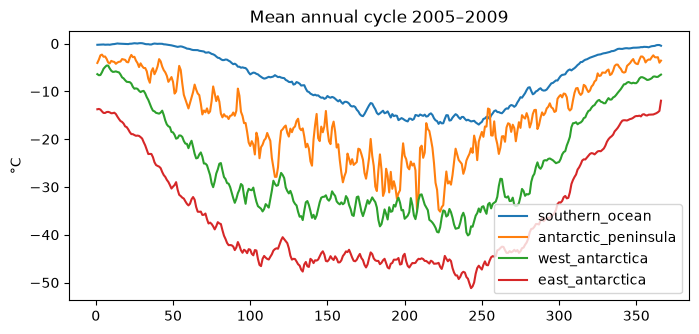

In [3]:
g = cube.grid; area = g['area_km2']
w = cube.window('t2m', '2009-12-31', 1826)
d = pd.date_range(end='2009-12-31', periods=1826)
fig, ax = plt.subplots(figsize=(8, 3.5))
for r, nm in enumerate(g['region_names']):
    m = g['region'] == r
    s = pd.Series((w[:, m] * area[m]).sum(1) / area[m].sum(), index=d)
    s.groupby(s.index.dayofyear).mean().plot(ax=ax, label=str(nm))
ax.set_ylabel('°C'); ax.legend(); ax.set_title('Mean annual cycle 2005–2009')

## Anomaly variability: weekly-anomaly σ (training climatology, JJA)

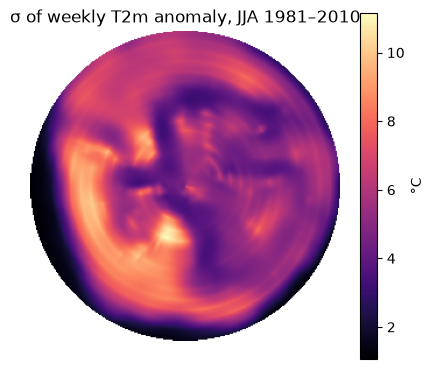

In [4]:
import glob
from aethentra.temperature.labels.labels import Sigma
p = ROOT / 'models/ml02/artifacts' / f'anomaly_sigma_{cube.source}.npz'
if p.exists():
    s = Sigma.load(p)
    plt.figure(figsize=(5, 4.5)); plt.imshow(cube.to_grid(s.sig['JJA'])[41:307, 25:291], cmap='magma'); plt.colorbar(label='°C')
    plt.title('σ of weekly T2m anomaly, JJA 1981–2010'); plt.axis('off')
else:
    print('sigma not fitted yet')

## Data-quality figures (generated by `scripts/ml02/validate_data.py`)

coverage_heatmap.png


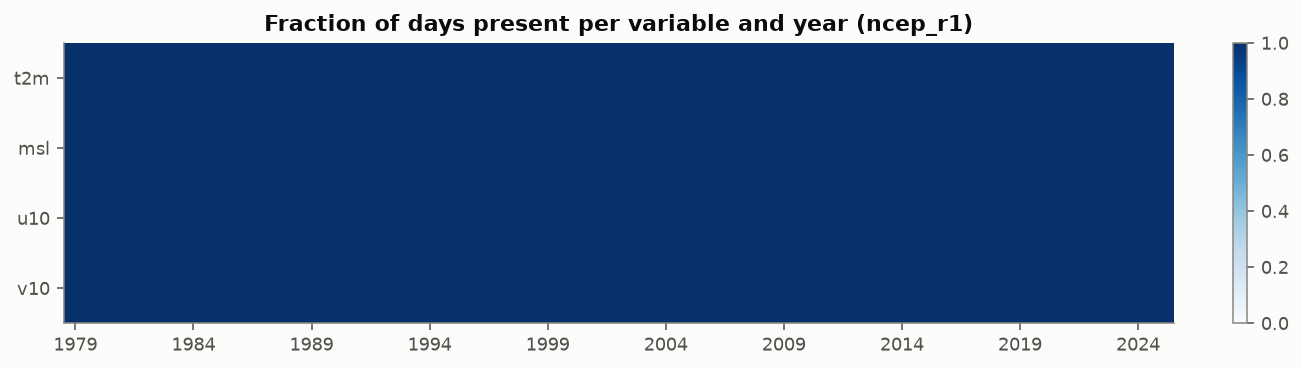

domain_mean_t2m.png


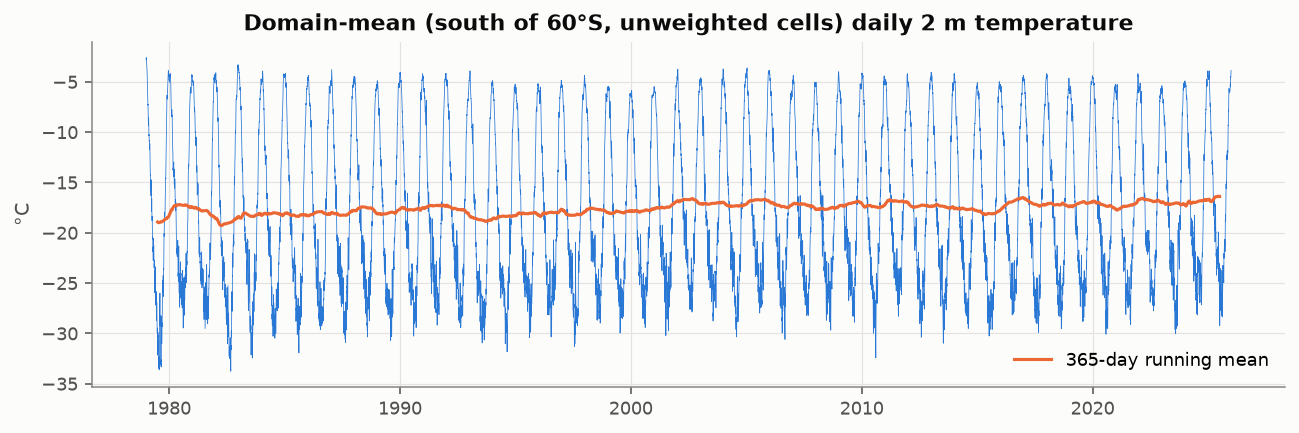

seasonal_cycle_regions.png


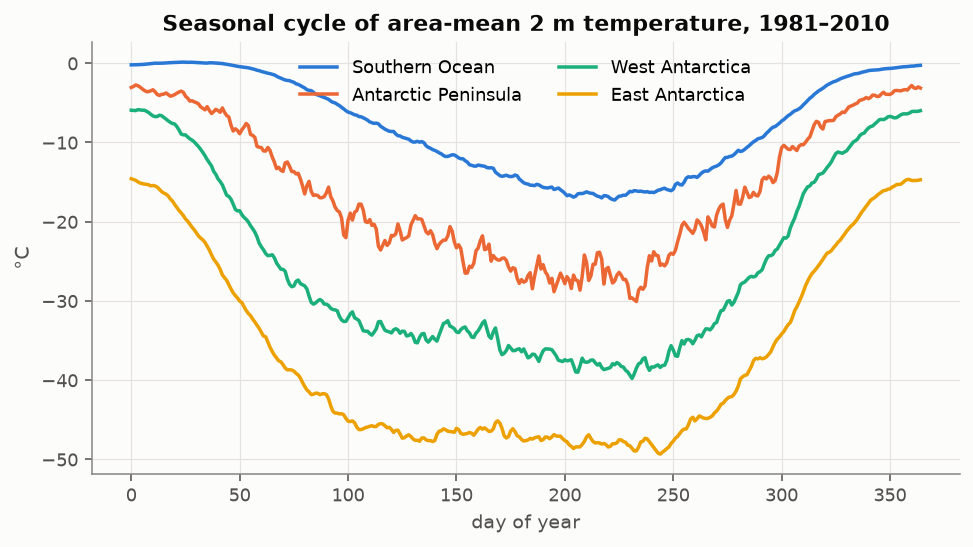

spatial_coverage.png


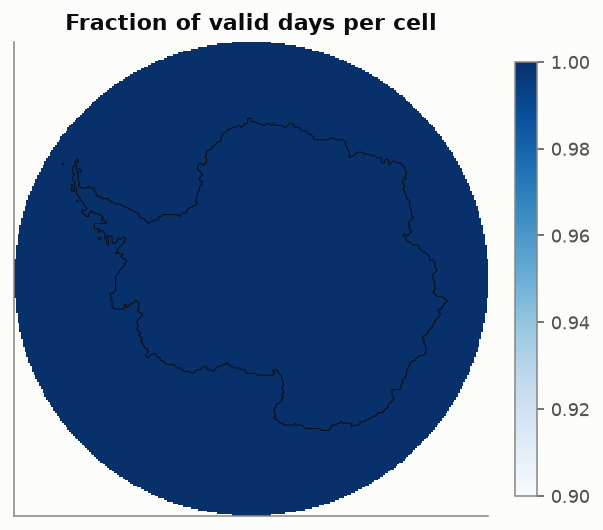

t2m_distribution.png


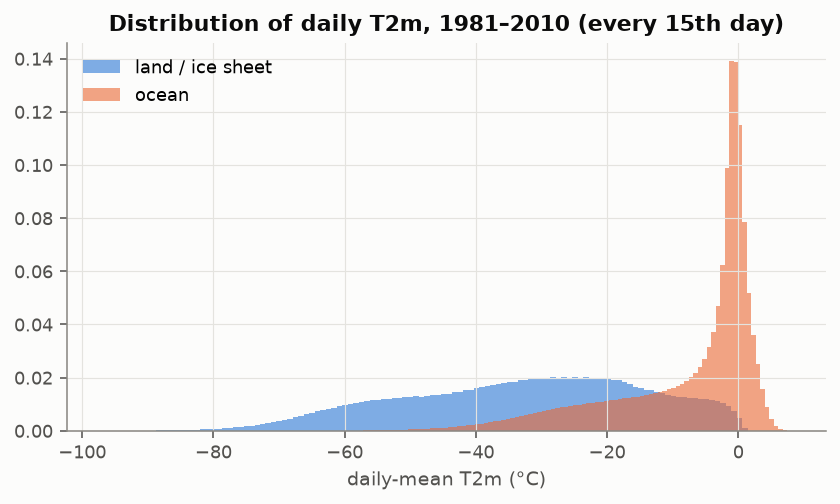

t2m_maps_1981_2010.png


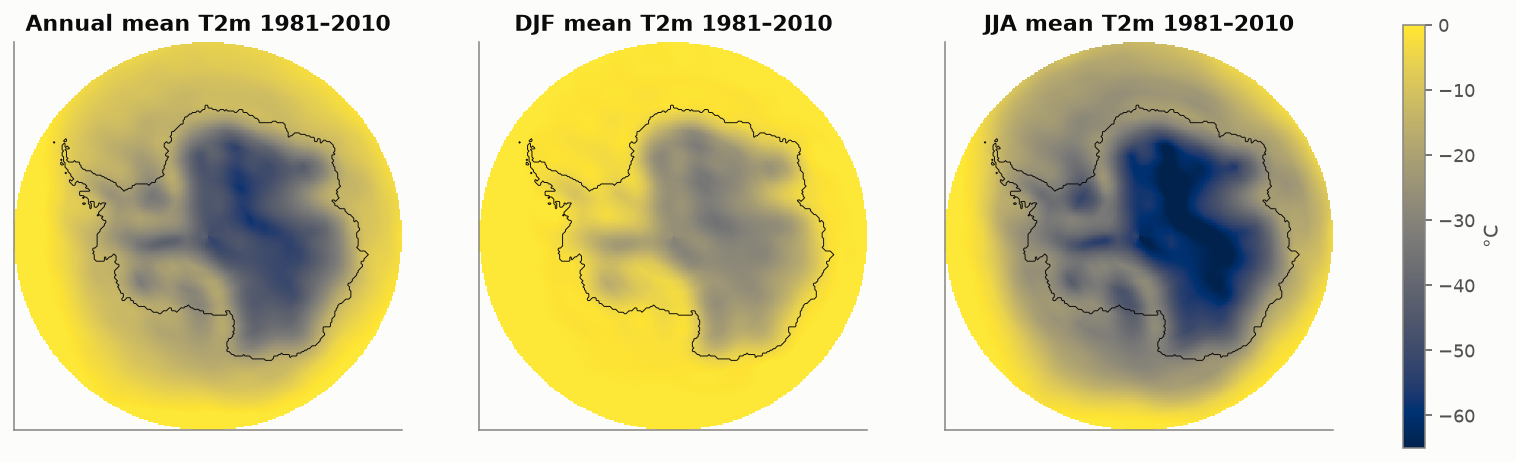

variable_correlation.png


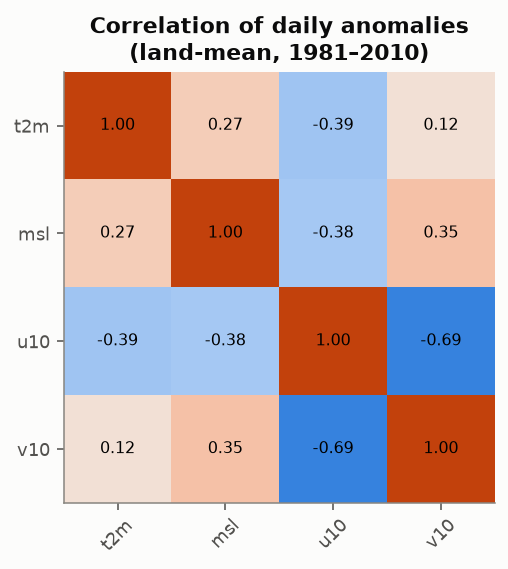

In [5]:
from IPython.display import Image, display
for f in sorted((ROOT / 'outputs/ml02/figures/data_quality').glob('*.png')):
    print(f.name); display(Image(filename=str(f), width=700))